# 02 · Data visualization

This shared EDA notebook examines class balance, feature distributions by diagnosis, and relationships among representative measurements. It uses the raw dataset without modifying it. The all-empty `Unnamed: 32` column is excluded from analyses; `id` is never treated as a predictor.

**Interpretation guardrail:** plots are exploratory. Separation in this dataset does not demonstrate clinical performance or generalization. No feature will be dropped or transformed here based only on appearance. There is no temporal field in the supplied table, so temporal plots are not applicable.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook', palette=['#0072B2', '#D55E00'])

DATA_PATH = Path('../data/raw/Raw_Breast_Cancer_Data.csv')
TARGET = 'diagnosis'
ID_COLUMN = 'id'
CLASS_ORDER = ['B', 'M']
COLORS = {'B': '#0072B2', 'M': '#D55E00'}
df_raw = pd.read_csv(DATA_PATH)
empty_columns = df_raw.columns[df_raw.isna().all()].tolist()
df = df_raw.drop(columns=empty_columns).copy()
features = df.drop(columns=[TARGET, ID_COLUMN])
print(f'Rows: {len(df):,}; numeric measurements: {features.shape[1]}')
print(f'Excluded all-empty columns: {empty_columns}')
print(f'Target labels: {sorted(df[TARGET].dropna().unique())}')

Rows: 569; numeric measurements: 30
Excluded all-empty columns: ['Unnamed: 32']
Target labels: ['B', 'M']


## 1. How many records belong to each diagnosis?

The first chart shows counts and within-dataset percentages. Use the class counts to keep later validation stratified and to interpret recall/precision alongside any aggregate score.

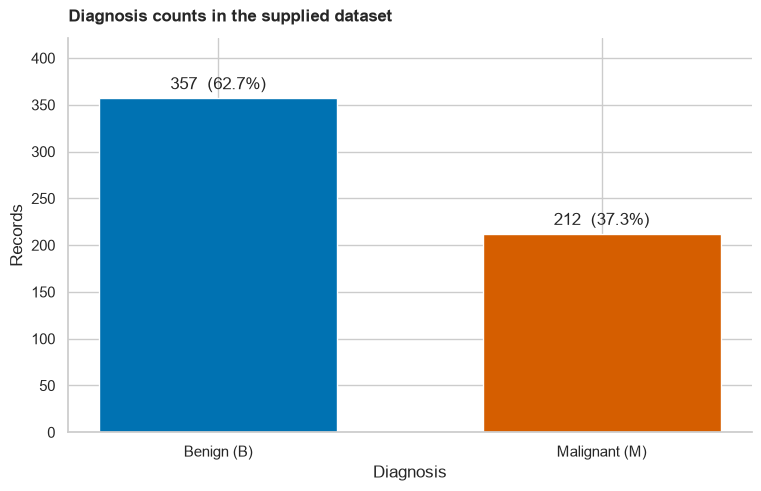

,count,percent
diagnosis,,
B,357,62.7
M,212,37.3


In [2]:
counts = df[TARGET].value_counts().reindex(CLASS_ORDER)
percentages = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(7.5, 4.8), constrained_layout=True)
bars = ax.bar(["Benign (B)", "Malignant (M)"], counts.values, color=[COLORS[c] for c in CLASS_ORDER], width=0.62)
ax.set_title('Diagnosis counts in the supplied dataset', loc='left', weight='bold', pad=12)
ax.set_ylabel('Records')
ax.set_xlabel('Diagnosis')
ax.spines[['top', 'right']].set_visible(False)
ax.bar_label(bars, labels=[f'{v:,}  ({p:.1f}%)' for v, p in zip(counts.values, percentages.values)], padding=4)
ax.set_ylim(0, counts.max() * 1.18)
plt.show()
display(pd.DataFrame({'count': counts, 'percent': percentages.round(1)}))

## 2. How do selected measurements vary by diagnosis?

Overlaid histograms with density scaling compare representative mean measurements without implying that these four features are the full modeling set. Evaluate overlap as well as differences; scaling and correlated predictors will be handled inside model pipelines later.

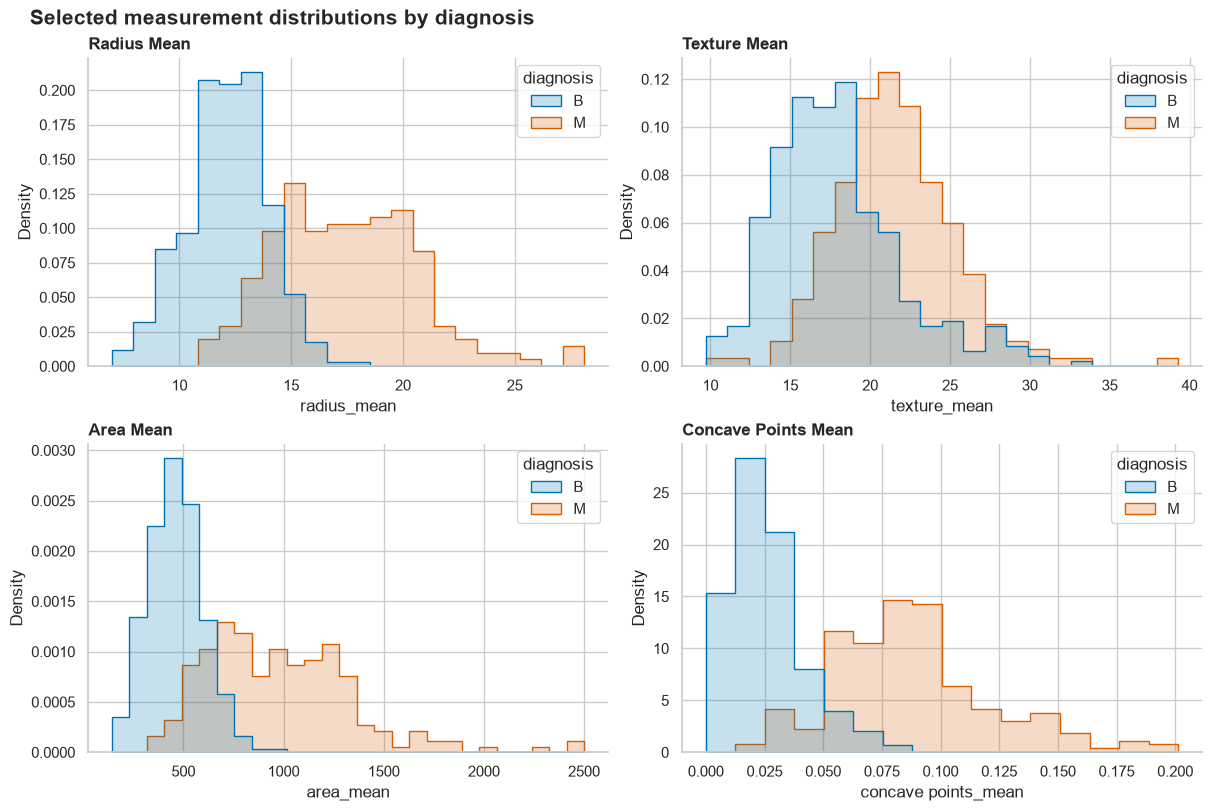

In [3]:
distribution_features = ['radius_mean', 'texture_mean', 'area_mean', 'concave points_mean']
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, feature in zip(axes.flat, distribution_features):
    sns.histplot(data=df, x=feature, hue=TARGET, hue_order=CLASS_ORDER,
                 stat='density', common_norm=False, element='step', fill=True,
                 alpha=0.22, palette=COLORS, ax=ax)
    ax.set_title(feature.replace('_', ' ').title(), loc='left', weight='bold')
    ax.set_ylabel('Density')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Selected measurement distributions by diagnosis', fontsize=15, weight='bold', x=0.02, ha='left')
plt.show()

## 3. Which selected measurements move together?

The correlation heatmap uses the pooled records and is descriptive only. It can reveal redundancy among geometric measurements; it does not establish causality or feature importance. Correlation will inform interpretation, not automatic feature removal.

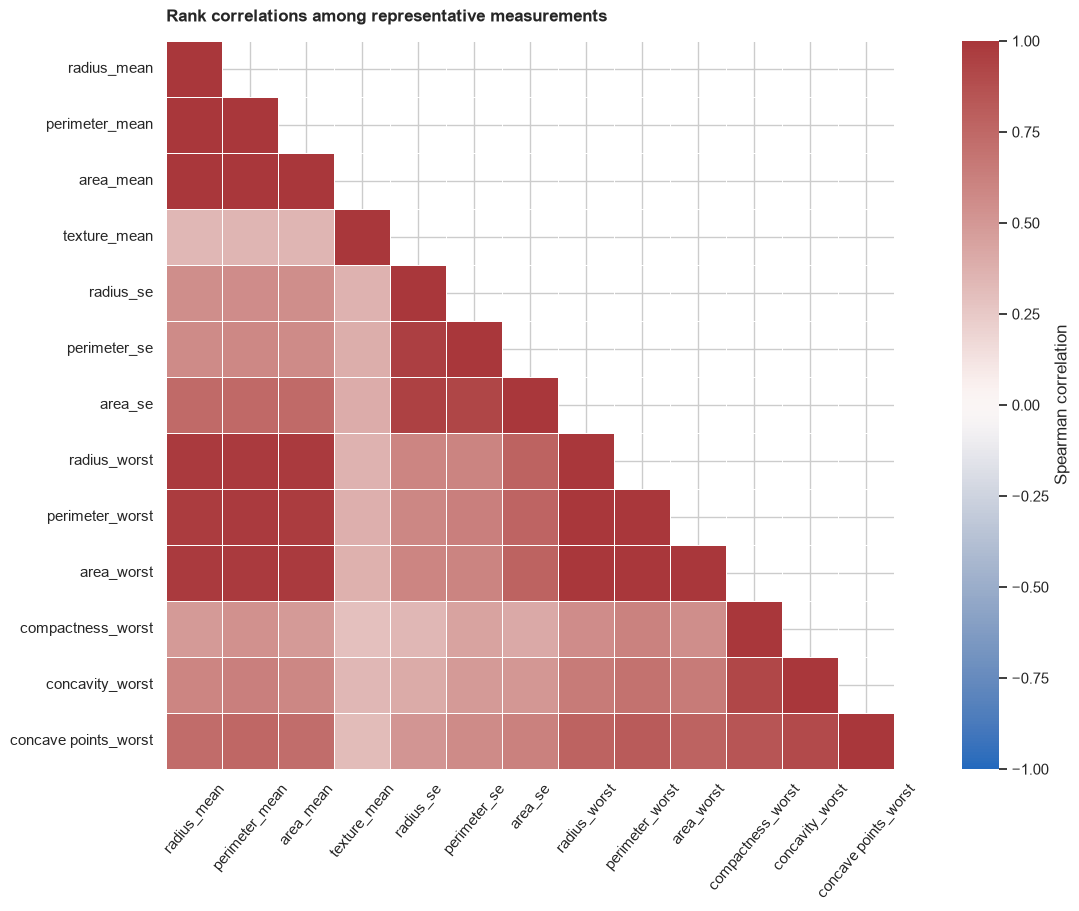

In [4]:
correlation_features = [
    'radius_mean', 'perimeter_mean', 'area_mean', 'texture_mean',
    'radius_se', 'perimeter_se', 'area_se',
    'radius_worst', 'perimeter_worst', 'area_worst',
    'compactness_worst', 'concavity_worst', 'concave points_worst',
]
corr = df[correlation_features].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
sns.heatmap(corr, mask=mask, cmap='vlag', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Rank correlations among representative measurements', loc='left', weight='bold', pad=14)
ax.tick_params(axis='x', rotation=50)
ax.tick_params(axis='y', rotation=0)
plt.show()

## 4. Compare spread and outliers across diagnoses

Boxplots summarize medians and spread for four representative measurements. Individual points are omitted to keep the view readable; the distributions above show shape and overlap. Outliers are not automatically errors and should not be removed without a data-quality reason.

In [ ]:
spread_features = ['radius_mean', 'texture_mean', 'area_mean', 'concave points_mean']
plot_data = df.melt(id_vars=TARGET, value_vars=spread_features, var_name='measurement', value_name='value')
fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
sns.boxplot(data=plot_data, x='measurement', y='value', hue=TARGET, hue_order=CLASS_ORDER,
            palette=COLORS, showfliers=False, width=0.7, legend=False, ax=ax)
ax.set_title('Measurement spread by diagnosis (fliers hidden for readability)', loc='left', weight='bold', pad=12)
ax.set_xlabel('Measurement')
ax.set_ylabel('Observed value')
ax.set_xticks(range(len(spread_features)), labels=[s.replace('_', ' ').title() for s in spread_features])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=COLORS['B'], label='Benign (B)'),
                    Patch(facecolor=COLORS['M'], label='Malignant (M)')],
          title='Diagnosis', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## Interpretation after EDA 

- **Class balance:** the dataset contains 357 benign cases (62.7%) and 212 malignant cases (37.3%). This is a moderate imbalance, so preserve class proportions in splits and report malignant-class recall alongside precision and F1.
- **Distributions:** malignant cases tend toward larger `radius_mean`, `area_mean`, and `concave points_mean`; their distributions still overlap the benign distributions to varying degrees. `texture_mean` shows substantial overlap. These are univariate visual patterns, not validated decision thresholds.
- **Correlations:** radius, perimeter, and area measurements are strongly positively correlated across mean, standard-error, and worst groups. Several worst-shape measurements also move together. This redundancy is a multicollinearity and interpretation consideration for Logistic Regression; it does not justify dropping features by itself.
- **Spread:** the saved boxplot compares scales with very different units, especially `area_mean`, so within-feature diagnosis differences are hard to compare across the shared y-axis. The original output also showed a Matplotlib tick-label warning and incorrect duplicate legend colors. The plotting cell has been corrected; rerun that cell to regenerate its output. Do not use the old boxplot legend to interpret class-specific medians.
- **Data handling:** the all-empty `Unnamed: 32` field was excluded, while the raw CSV remained unchanged. No visual pattern alone justifies removing rows or measurements.

### Self-critique

These plots cover only four distributions and a selected correlation subset from a modest, curated dataset. Strong visual separation may overstate performance on new populations, and the pooled correlation heatmap does not reveal class-conditional relationships. The saved boxplot output also had a mislabeled color legend and a tick-label warning; its code is corrected, but the figure must be rerun before relying on that panel. The plots remain exploratory, and later model choices must rely on leakage-safe validation and a held-out test set.